s=0.02: acceptance rate = 0.9637, integrated autocorrelation time of alpha = 535.65
s=0.5: acceptance rate = 0.3658, integrated autocorrelation time of alpha = 7.75
s=5: acceptance rate = 0.0077, integrated autocorrelation time of alpha = 158.42


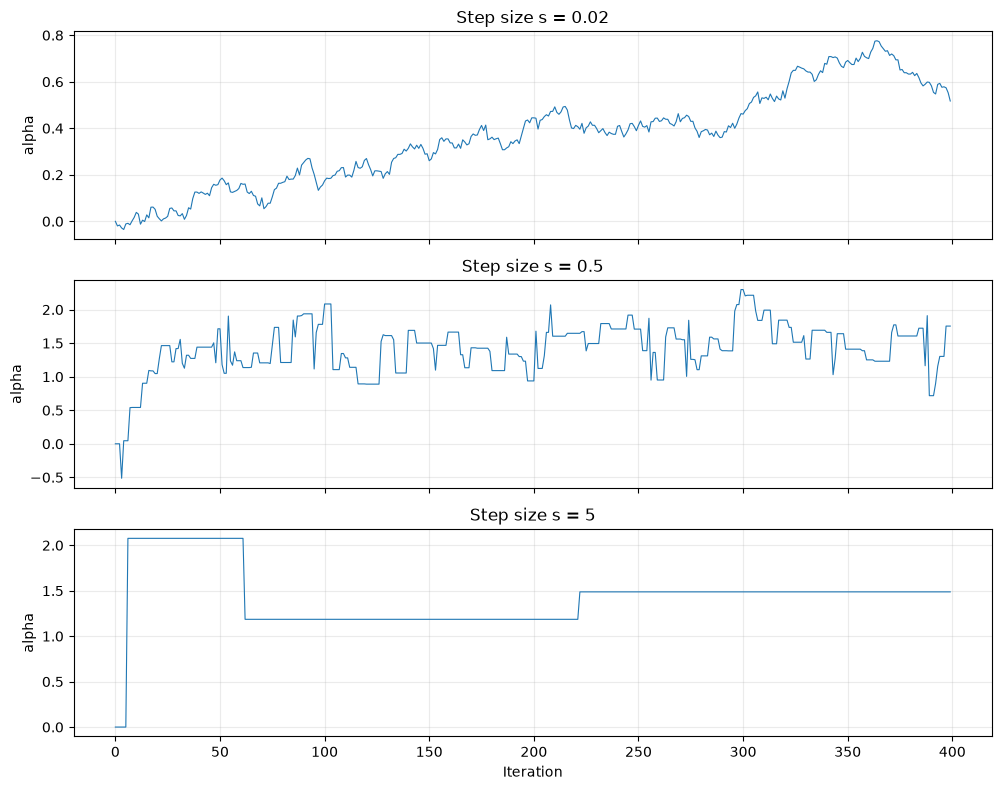


Selected step size: 0.5
Post-burn-in draws: 45000
Alpha chain: mean, 90% interval = (np.float64(1.4822275916450371), np.float64(1.0208014777071954), np.float64(1.9308516064946262))
Beta chain: mean, 90% interval = (np.float64(0.7699245877204985), np.float64(0.37152061732002356), np.float64(1.379319760096402))
Alpha integrated autocorrelation time = 7.75

GRID POSTERIOR RESULTS
Alpha: mean = 1.4827, 90% interval = [1.04 1.92]
Beta: mean = 0.7755, 90% interval = [0.37232059 1.37850558]


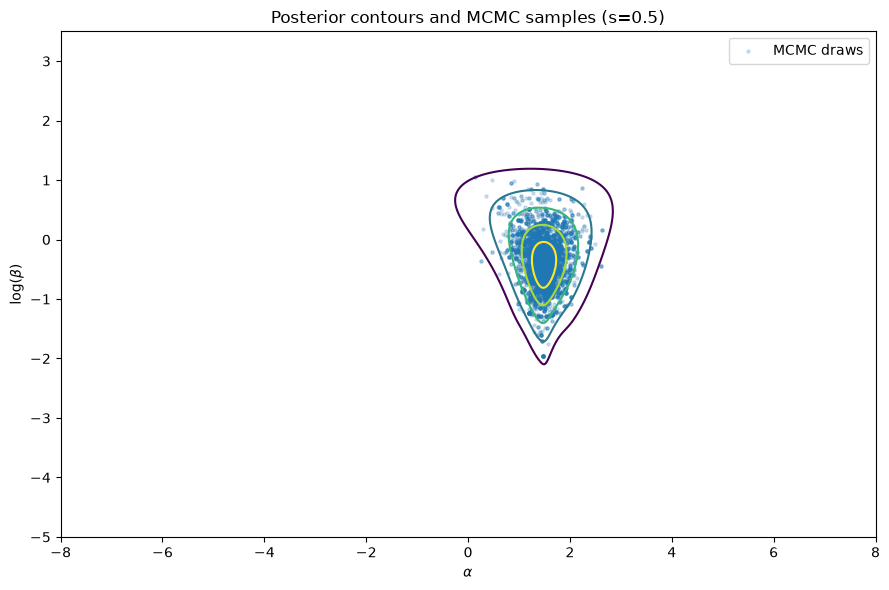


OBSERVED DATA
Sample mean = 1.6713
Sample median = 1.5000


In [8]:
# 1(c)
import os
import numpy as np
import matplotlib.pyplot as plt

# Observed data
x = np.array([
    -1.77, 2.47, 1.34, 2.18, 13.05,
    1.60, 1.50, -1.97, 0.79, 1.50,
    2.00, 2.63, 1.19, -2.31, 0.87
])
n = len(x)

# Log of the transformed posterior, up to a constant
def log_g(z):
    alpha, b = z
    beta2 = np.exp(2 * b)
    return n * b - np.sum(np.log(beta2 + (x - alpha)**2))

# Random-walk Metropolis algorithm
def run_mcmc(s, T=50000, seed=123):
    rng = np.random.default_rng(seed)
    chain = np.zeros((T + 1, 2))
    accepted = 0

    for t in range(T):
        current = chain[t]
        proposal = current + s * rng.normal(size=2)

        log_ratio = log_g(proposal) - log_g(current)

        if np.log(rng.random()) < min(0.0, log_ratio):
            chain[t + 1] = proposal
            accepted += 1
        else:
            chain[t + 1] = current

    return chain, accepted / T

# Integrated autocorrelation time using the initial-positive-pair method
def integrated_autocorrelation_time(values):
    values = np.asarray(values, dtype=float)
    values = values - values.mean()
    N = len(values)

    # FFT-based autocorrelation
    fft = np.fft.rfft(values, n=2 * N)
    acov = np.fft.irfft(fft * np.conjugate(fft))[:N]
    acf = acov / acov[0]

    tau = 1.0
    k = 1

    while k + 1 < N:
        pair_sum = acf[k] + acf[k + 1]
        if pair_sum <= 0:
            break
        tau += 2 * pair_sum
        k += 2

    return tau

# Run all three chains
step_sizes = [0.02, 0.5, 5]
chains = {}
acceptance = {}

for j, s in enumerate(step_sizes):
    chains[s], acceptance[s] = run_mcmc(s, seed=123 + j)
    print(
        f"s={s}: acceptance rate = {acceptance[s]:.4f}, "
        f"integrated autocorrelation time of alpha = "
        f"{integrated_autocorrelation_time(chains[s][5000:, 0]):.2f}"
    )

# Plot the first 400 alpha values for each step size
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for ax, s in zip(axes, step_sizes):
    ax.plot(np.arange(400), chains[s][:400, 0], linewidth=0.8)
    ax.set_title(f"Step size s = {s}")
    ax.set_ylabel("alpha")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Iteration")
fig.tight_layout()

os.makedirs(os.path.expanduser("~/Downloads"), exist_ok=True)

plt.savefig(
    os.path.expanduser("~/Downloads/Second.pdf"),
    bbox_inches="tight"
)
plt.show()

# Select the best step size using the estimated autocorrelation times
taus = {
    s: integrated_autocorrelation_time(chains[s][5000:, 0])
    for s in step_sizes
}
best_s = min(taus, key=taus.get)
best_chain = chains[best_s][5001:]  # Discard first 5000 transitions

alpha_chain = best_chain[:, 0]
beta_chain = np.exp(best_chain[:, 1])

def summarize(values):
    return (
        np.mean(values),
        np.quantile(values, 0.05),
        np.quantile(values, 0.95)
    )

print(f"\nSelected step size: {best_s}")
print(f"Post-burn-in draws: {len(best_chain)}")
print(f"Alpha chain: mean, 90% interval = {summarize(alpha_chain)}")
print(f"Beta chain: mean, 90% interval = {summarize(beta_chain)}")
print(f"Alpha integrated autocorrelation time = "
      f"{integrated_autocorrelation_time(alpha_chain):.2f}")

# Grid approximation to the exact transformed posterior
alpha_grid = np.linspace(-8, 8, 601)
b_grid = np.linspace(-5, 3.5, 501)
A, B = np.meshgrid(alpha_grid, b_grid)

log_grid = n * B.copy()

for xi in x:
    log_grid -= np.log(np.exp(2 * B) + (xi - A)**2)

# Normalize grid weights; equal grid spacing cancels in weighted summaries
weights = np.exp(log_grid - np.max(log_grid))
weights /= weights.sum()

def weighted_mean(values, weights):
    return np.sum(values * weights)

def weighted_quantile(values, weights, probs):
    values = np.asarray(values).ravel()
    weights = np.asarray(weights).ravel()
    order = np.argsort(values)
    values = values[order]
    weights = weights[order]
    cumulative = np.cumsum(weights)
    cumulative /= cumulative[-1]
    return np.interp(probs, cumulative, values)

alpha_mean_grid = weighted_mean(A, weights)
beta_mean_grid = weighted_mean(np.exp(B), weights)

alpha_interval_grid = weighted_quantile(
    A, weights, [0.05, 0.95]
)
beta_interval_grid = weighted_quantile(
    np.exp(B), weights, [0.05, 0.95]
)

print("\nGRID POSTERIOR RESULTS")
print(f"Alpha: mean = {alpha_mean_grid:.4f}, "
      f"90% interval = {alpha_interval_grid}")
print(f"Beta: mean = {beta_mean_grid:.4f}, "
      f"90% interval = {beta_interval_grid}")

# Contours of the exact posterior in (alpha, log(beta)) coordinates
plt.figure(figsize=(9, 6))
levels = np.max(log_grid) - np.array([8, 5, 3, 1.5, 0.5])
plt.contour(A, B, log_grid, levels=np.sort(levels))
plt.scatter(
    alpha_chain[:5000], best_chain[:5000, 1],
    s=5, alpha=0.20, label="MCMC draws"
)
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\log(\beta)$")
plt.title(f"Posterior contours and MCMC samples (s={best_s})")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.expanduser("~/Downloads/lighthouse_posterior_contour.pdf"),
    bbox_inches="tight"
)
plt.show()

# Compare sample mean and median of the observations
print("\nOBSERVED DATA")
print(f"Sample mean = {np.mean(x):.4f}")
print(f"Sample median = {np.median(x):.4f}")

   n Estimator  Average of estimates  Median of estimates  IQR/1.349  25th percentile  75th percentile
  10      Mean                1.8228               1.4924     1.1658           0.7513           2.3239
  10    Median                1.5064               1.4986     0.3876           1.2369           1.7597
 100      Mean                1.2961               1.5223     1.2345           0.6481           2.3133
 100    Median                1.4997               1.5028     0.1270           1.4146           1.5859
1000      Mean                2.8605               1.4859     1.2384           0.6631           2.3337
1000    Median                1.4997               1.4992     0.0380           1.4737           1.5249


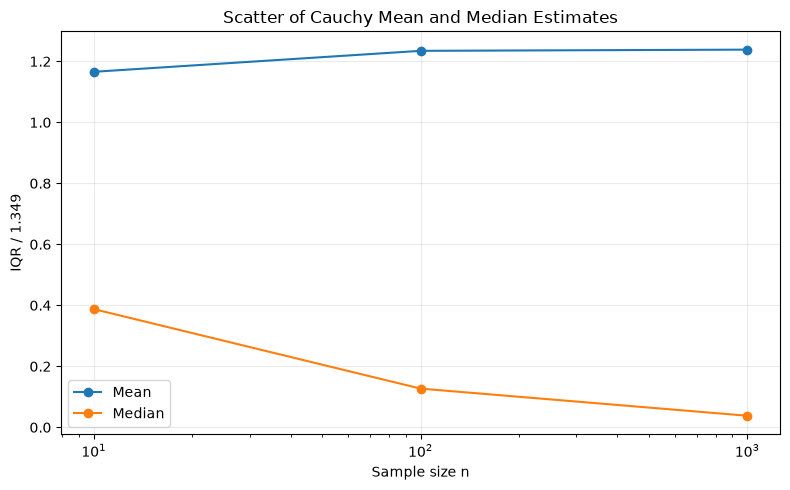

In [2]:
# 1(d)
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)

alpha_true = 1.5
beta_true = 0.8
sample_sizes = [10, 100, 1000]
num_datasets = 2000

results = []
estimates = {}

for n in sample_sizes:
    # Cauchy(alpha, beta) observations
    data = alpha_true + beta_true * rng.standard_cauchy(
        size=(num_datasets, n)
    )

    means = np.mean(data, axis=1)
    medians = np.median(data, axis=1)

    estimates[(n, "Mean")] = means
    estimates[(n, "Median")] = medians

    for name, values in [("Mean", means), ("Median", medians)]:
        q25, q75 = np.quantile(values, [0.25, 0.75])
        scatter = (q75 - q25) / 1.349

        results.append({
            "n": n,
            "Estimator": name,
            "Average of estimates": np.mean(values),
            "Median of estimates": np.median(values),
            "IQR/1.349": scatter,
            "25th percentile": q25,
            "75th percentile": q75
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

# Plot estimator scatter against sample size
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for name in ["Mean", "Median"]:
    subset = results_df[results_df["Estimator"] == name]
    plt.plot(
        subset["n"], subset["IQR/1.349"],
        marker="o", label=name
    )

plt.xscale("log")
plt.xlabel("Sample size n")
plt.ylabel("IQR / 1.349")
plt.title("Scatter of Cauchy Mean and Median Estimates")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    os.path.expanduser("~/Downloads/cauchy_estimator_scatter.pdf"),
    bbox_inches="tight"
)
plt.show()

In [3]:
#2
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs(os.path.expanduser("~/Downloads"), exist_ok=True)

rates = np.array([3.0, 2.0, 1.5, 1.2, 1.0, 0.75])
n = len(rates)
full_mask = (1 << n) - 1

# E[mask] = expected time until everyone in the subset finishes
# last[mask][i] = probability student i finishes last
E = {0: 0.0}
last = {0: np.zeros(n)}

for mask in range(1, 1 << n):
    idx = [i for i in range(n) if mask & (1 << i)]
    total_rate = rates[idx].sum()

    E[mask] = 1.0 / total_rate
    last_prob = np.zeros(n)

    for i in idx:
        sub = mask & ~(1 << i)
        p_first = rates[i] / total_rate

        E[mask] += p_first * E[sub]

        if sub == 0:
            last_prob[i] += p_first
        else:
            last_prob += p_first * last[sub]

    last[mask] = last_prob


def alternating_mean(rates):
    n = len(rates)
    answer = 0.0

    for mask in range(1, 1 << n):
        total = sum(
            rates[i] for i in range(n)
            if mask & (1 << i)
        )
        size = mask.bit_count()
        answer += (-1)**(size + 1) / total

    return answer


exact_mean = E[full_mask]
formula_mean = alternating_mean(rates)
last_prob = last[full_mask]

print("SIX-STUDENT RESULTS")
print(f"Expected M (subset recursion) = {exact_mean:.6f}")
print(f"Expected M (alternating formula) = {formula_mean:.6f}")

print("\nProbability each student finishes last:")
for i, p in enumerate(last_prob, start=1):
    print(f"Student {i}, rate {rates[i-1]:.2f}: {p:.6f}")


    rng = np.random.default_rng(2026)
Nsim = 200_000

times = rng.exponential(
    scale=1.0 / rates,
    size=(Nsim, n)
)

M = times.max(axis=1)
first_time = times.min(axis=1)
first_student = times.argmin(axis=1)

sim_mean = M.mean()
sim_se = M.std(ddof=1) / np.sqrt(Nsim)

print("\nSIMULATION RESULTS")
print(f"Simulated E[M] = {sim_mean:.6f}")
print(f"Monte Carlo standard error = {sim_se:.6f}")
print(f"Exact E[M] = {exact_mean:.6f}")
print(f"Simulated mean first finishing time = {first_time.mean():.6f}")
print(f"Exact mean first finishing time = {1 / rates.sum():.6f}")

print("\nFirst finisher probabilities:")
for i in range(n):
    conditional_mean = first_time[first_student == i].mean()

    print(
        f"Student {i+1}: simulated probability = "
        f"{np.mean(first_student == i):.4f}, "
        f"exact probability = {rates[i]/rates.sum():.4f}, "
        f"conditional mean first time = {conditional_mean:.6f}"
    )

SIX-STUDENT RESULTS
Expected M (subset recursion) = 2.107376
Expected M (alternating formula) = 2.107376

Probability each student finishes last:
Student 1, rate 3.00: 0.026786
Student 2, rate 2.00: 0.069532
Student 3, rate 1.50: 0.122988
Student 4, rate 1.20: 0.181252
Student 5, rate 1.00: 0.240983
Student 6, rate 0.75: 0.358459

SIMULATION RESULTS
Simulated E[M] = 2.104872
Monte Carlo standard error = 0.002797
Exact E[M] = 2.107376
Simulated mean first finishing time = 0.105745
Exact mean first finishing time = 0.105820

First finisher probabilities:
Student 1: simulated probability = 0.3166, exact probability = 0.3175, conditional mean first time = 0.105726
Student 2: simulated probability = 0.2115, exact probability = 0.2116, conditional mean first time = 0.106087
Student 3: simulated probability = 0.1598, exact probability = 0.1587, conditional mean first time = 0.105167
Student 4: simulated probability = 0.1258, exact probability = 0.1270, conditional mean first time = 0.105692
S

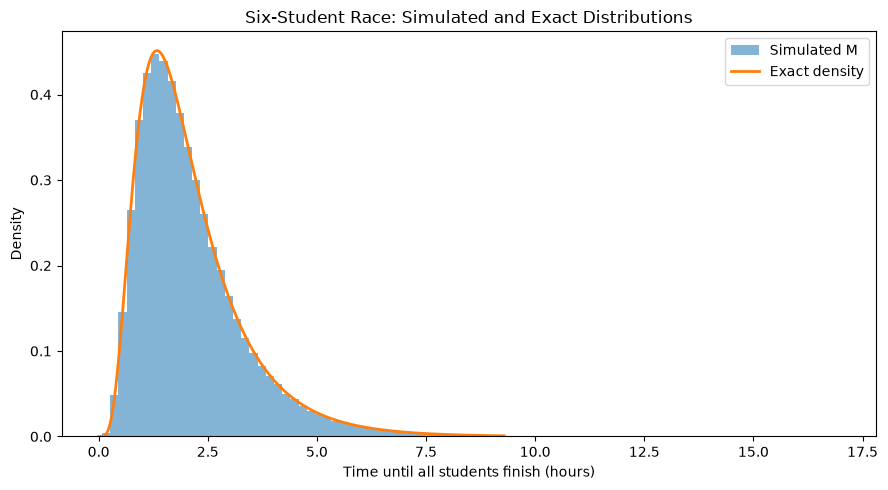

In [4]:
def exact_density_M(t, rates):
    density = np.zeros_like(t, dtype=float)

    for i, lam in enumerate(rates):
        term = lam * np.exp(-lam * t)

        for j, other_lam in enumerate(rates):
            if j != i:
                term *= 1 - np.exp(-other_lam * t)

        density += term

    return density


t_grid = np.linspace(0, np.quantile(M, 0.999), 1000)

plt.figure(figsize=(9, 5))
plt.hist(
    M, bins=90, density=True, alpha=0.55,
    label="Simulated M"
)
plt.plot(
    t_grid, exact_density_M(t_grid, rates),
    linewidth=2, label="Exact density"
)

plt.xlabel("Time until all students finish (hours)")
plt.ylabel("Density")
plt.title("Six-Student Race: Simulated and Exact Distributions")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.expanduser("~/Downloads/race_last_student.pdf"),
    bbox_inches="tight"
)
plt.show()


EXPECTED TIME FOR RATES lambda_i = i
 k     E[M]  2 ln(2)
 1 1.000000 1.386294
 2 1.166667 1.386294
 3 1.216667 1.386294
 4 1.236111 1.386294
 5 1.244902 1.386294
 6 1.249295 1.386294
 7 1.251653 1.386294
 8 1.252989 1.386294
 9 1.253780 1.386294
10 1.254265 1.386294
11 1.254571 1.386294
12 1.254769 1.386294


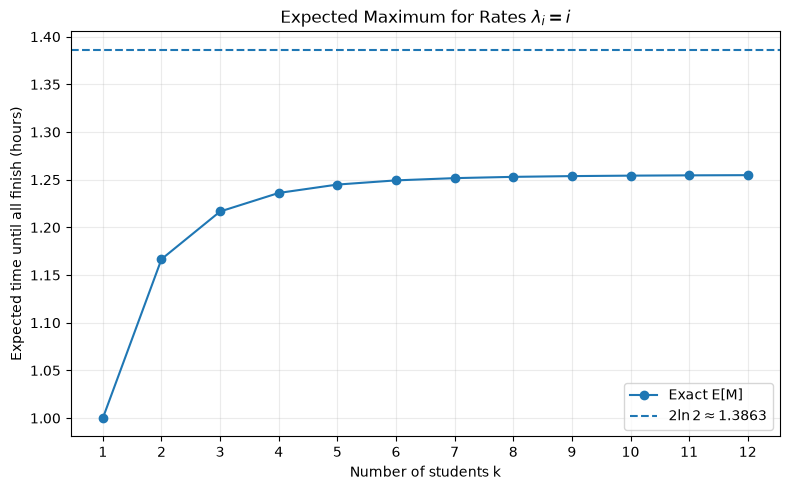

In [5]:
ks = np.arange(1, 13)
expected_times = []

for k in ks:
    rates_k = np.arange(1, k + 1, dtype=float)
    expected_times.append(alternating_mean(rates_k))

expected_times = np.array(expected_times)
bound = 2 * np.log(2)

print("\nEXPECTED TIME FOR RATES lambda_i = i")
print(pd.DataFrame({
    "k": ks,
    "E[M]": expected_times,
    "2 ln(2)": np.full(len(ks), bound)
}).round(6).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(ks, expected_times, marker="o", label="Exact E[M]")
plt.axhline(
    bound, linestyle="--",
    label=r"$2\ln 2 \approx 1.3863$"
)

plt.xlabel("Number of students k")
plt.ylabel("Expected time until all finish (hours)")
plt.title(r"Expected Maximum for Rates $\lambda_i=i$")
plt.xticks(ks)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.expanduser("~/Downloads/race_expected_time_vs_k.pdf"),
    bbox_inches="tight"
)
plt.show()

METEOR SHOWER SIMULATION
Rate: 4.0 meteors per hour
Simulation length: 200,000 hours
Output directory: /Users/youssef/Downloads

Simulating exponential-gap construction...
Simulating Poisson-count + uniform-point construction...
Exponential-gap arrivals: 800,746
Uniform-point arrivals:   799,171


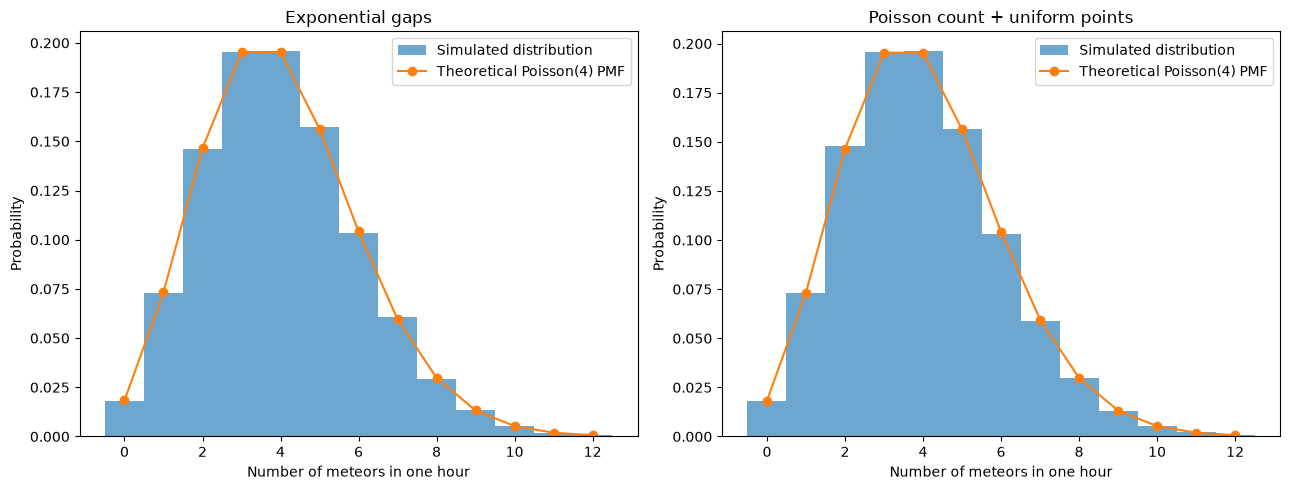


MEANS AND VARIANCES OF N(1)

Exponential gaps
Sample mean:     4.00373000
Sample variance: 3.99860608

Poisson + uniform points
Sample mean:     3.99585500
Sample variance: 3.99408779

Theoretical mean:     4
Theoretical variance: 4


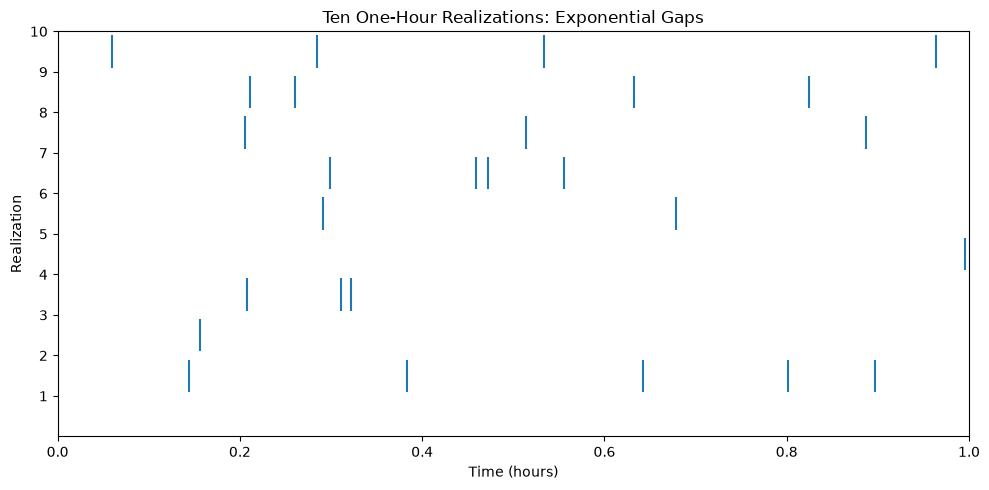

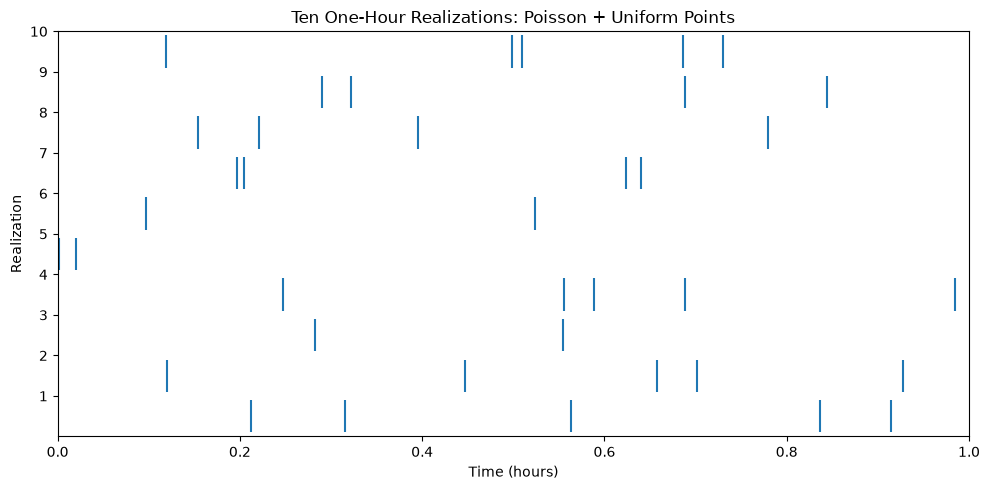


THIRD ARRIVAL TIME T3 -- EXPONENTIAL GAP SIMULATION
Number of T3 samples: 200,000
Simulated mean of T3:     0.75022192
Theoretical mean of T3:   0.75000000
Simulated variance of T3: 0.18870908
Theoretical variance:     0.18750000


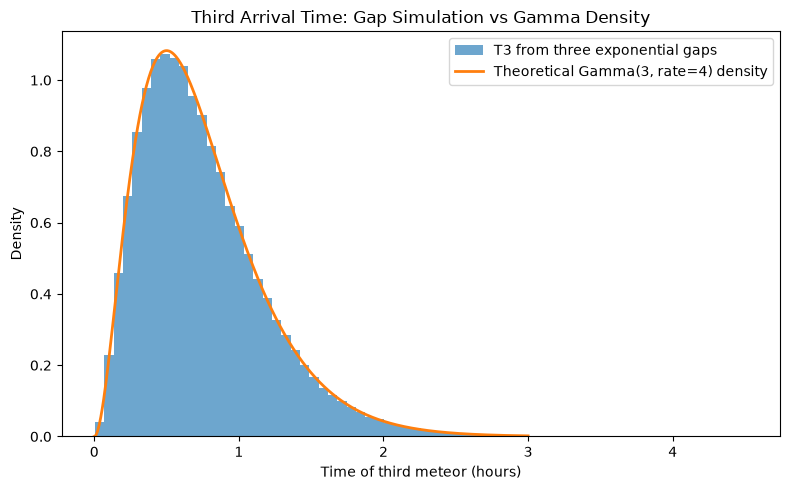


CONDITIONAL ESTIMATES GIVEN N(1) = 3

Exponential gaps
Hours with N(1)=3: 39,071
Estimated conditional probability: 0.12423537
Theoretical probability:            0.12500000
Estimated conditional mean:         0.24947104 hours
Theoretical conditional mean:       0.25000000 hours

Poisson + uniform points
Hours with N(1)=3: 39,090
Estimated conditional probability: 0.12627270
Theoretical probability:            0.12500000
Estimated conditional mean:         0.25087326 hours
Theoretical conditional mean:       0.25000000 hours

CORRELATION BETWEEN HALF-HOUR COUNTS
Exponential gaps: -0.00070841
Poisson + uniform points: -0.00204061
Theoretical unconditional correlation: 0
Approximate standard error near zero: 0.00223607
Conditional on N(1)=3, the two half-hour counts have correlation -1.

TOTAL VARIATION DISTANCE AND LOG-LOG SLOPE
Estimated log-log slope: 1.01155044
Fitted intercept:        0.08514724
TVD at delta_t=0.1:      0.12672565
TVD at delta_t=1/2000:   0.00050196
TVD / delta_t a

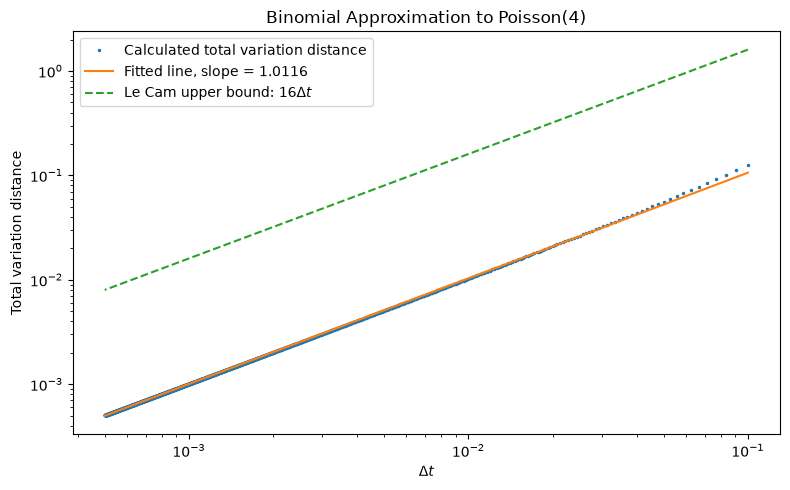


THEORETICAL CHECKS FOR PART (A)
P(no meteor in first 15 minutes): 0.36787944
P(third meteor arrives after 1 hour): 0.23810331

SIMULATION COMPLETE
All five PDF figures are saved in: /Users/youssef/Downloads
/Users/youssef/Downloads/01_meteor_count_histograms.pdf
/Users/youssef/Downloads/02_meteor_raster_gaps.pdf
/Users/youssef/Downloads/03_meteor_raster_uniform.pdf
/Users/youssef/Downloads/04_meteor_T3_gamma.pdf
/Users/youssef/Downloads/05_meteor_tvd_loglog.pdf


In [6]:

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, binom, gamma

LAMBDA = 4.0
HOURS = 200_000
N_SAMPLES = 200_000
SEED = 42

rng = np.random.default_rng(SEED)

os.makedirs(os.path.expanduser("~/Downloads"), exist_ok=True)
OUTPUT_DIR = os.path.expanduser("~/Downloads")

print("=" * 65)
print("METEOR SHOWER SIMULATION")
print("=" * 65)
print(f"Rate: {LAMBDA} meteors per hour")
print(f"Simulation length: {HOURS:,} hours")
print(f"Output directory: {OUTPUT_DIR}")


# ------------------------------------------------------------
# 1. METHOD 1: EXPONENTIAL INTERARRIVAL GAPS
# ------------------------------------------------------------

def simulate_gaps(T, rng):
    """Simulate arrival times on [0,T] using exponential gaps."""
    arrivals = []
    current_time = 0.0

    while True:
        current_time += rng.exponential(scale=1.0 / LAMBDA)

        if current_time >= T:
            break

        arrivals.append(current_time)

    return np.asarray(arrivals)


# ------------------------------------------------------------
# 2. METHOD 2: POISSON COUNT + UNIFORM POINTS
# ------------------------------------------------------------

def simulate_uniform(T, rng):
    """Generate a Poisson count and sort uniform arrival times."""
    n = rng.poisson(LAMBDA * T)
    arrivals = rng.uniform(0.0, T, size=n)
    return np.sort(arrivals)


# ------------------------------------------------------------
# 3. SIMULATE 200,000 HOURS WITH BOTH METHODS
# ------------------------------------------------------------

print("\nSimulating exponential-gap construction...")
arrivals_gap = simulate_gaps(HOURS, rng)

print("Simulating Poisson-count + uniform-point construction...")
arrivals_uniform = simulate_uniform(HOURS, rng)

print(f"Exponential-gap arrivals: {len(arrivals_gap):,}")
print(f"Uniform-point arrivals:   {len(arrivals_uniform):,}")


# ------------------------------------------------------------
# 4. COUNT ARRIVALS IN EACH HOUR
# ------------------------------------------------------------

def hourly_counts(arrivals, hours):
    """Count arrivals in [j,j+1) for j=0,...,hours-1."""
    return np.histogram(
        arrivals,
        bins=np.arange(hours + 1)
    )[0]


counts_gap = hourly_counts(arrivals_gap, HOURS)
counts_uniform = hourly_counts(arrivals_uniform, HOURS)


# ------------------------------------------------------------
# 5. HISTOGRAMS OF N(1) AND THEORETICAL POISSON(4) PMF
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, counts, title in [
    (axes[0], counts_gap, "Exponential gaps"),
    (axes[1], counts_uniform, "Poisson count + uniform points")
]:
    k = np.arange(13)

    ax.hist(
        counts,
        bins=np.arange(-0.5, 13.5, 1),
        density=True,
        alpha=0.65,
        label="Simulated distribution"
    )

    ax.plot(
        k,
        poisson.pmf(k, mu=LAMBDA),
        "o-",
        label="Theoretical Poisson(4) PMF"
    )

    ax.set_xlabel("Number of meteors in one hour")
    ax.set_ylabel("Probability")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "01_meteor_count_histograms.pdf"),
    format="pdf",
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 6. SAMPLE MEANS AND VARIANCES OF N(1)
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MEANS AND VARIANCES OF N(1)")
print("=" * 65)

for name, counts in [
    ("Exponential gaps", counts_gap),
    ("Poisson + uniform points", counts_uniform)
]:
    print(f"\n{name}")
    print(f"Sample mean:     {np.mean(counts):.8f}")
    print(f"Sample variance: {np.var(counts, ddof=1):.8f}")

print("\nTheoretical mean:     4")
print("Theoretical variance: 4")


# ------------------------------------------------------------
# 7. RASTER PLOTS: TEN ONE-HOUR REALIZATIONS PER METHOD
# ------------------------------------------------------------

def raster_plot(simulator, title, filename, seed):
    """Plot ten independent one-hour realizations."""
    local_rng = np.random.default_rng(seed)

    fig, ax = plt.subplots(figsize=(10, 5))

    for row in range(10):
        times = simulator(1.0, local_rng)
        ax.vlines(times, row + 0.1, row + 0.9)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 10)
    ax.set_xlabel("Time (hours)")
    ax.set_ylabel("Realization")
    ax.set_yticks(np.arange(1, 11))
    ax.set_title(title)

    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        format="pdf",
        bbox_inches="tight"
    )
    plt.show()


raster_plot(
    simulate_gaps,
    "Ten One-Hour Realizations: Exponential Gaps",
    "02_meteor_raster_gaps.pdf",
    seed=101
)

raster_plot(
    simulate_uniform,
    "Ten One-Hour Realizations: Poisson + Uniform Points",
    "03_meteor_raster_uniform.pdf",
    seed=202
)


# ------------------------------------------------------------
# 8. T3 FROM THREE INDEPENDENT EXPONENTIAL GAPS
# IMPORTANT: T3 IS NOT DRAWN DIRECTLY FROM A GAMMA DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("THIRD ARRIVAL TIME T3 -- EXPONENTIAL GAP SIMULATION")
print("=" * 65)

gaps_T3 = rng.exponential(
    scale=1.0 / LAMBDA,
    size=(N_SAMPLES, 3)
)

T3 = gaps_T3.sum(axis=1)

T3_mean = np.mean(T3)
T3_variance = np.var(T3, ddof=1)

print(f"Number of T3 samples: {N_SAMPLES:,}")
print(f"Simulated mean of T3:     {T3_mean:.8f}")
print(f"Theoretical mean of T3:   {3 / LAMBDA:.8f}")
print(f"Simulated variance of T3: {T3_variance:.8f}")
print(f"Theoretical variance:     {3 / LAMBDA**2:.8f}")

x = np.linspace(0, 3, 600)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    T3,
    bins=70,
    density=True,
    alpha=0.65,
    label="T3 from three exponential gaps"
)

ax.plot(
    x,
    gamma.pdf(x, a=3, scale=1.0 / LAMBDA),
    linewidth=2,
    label="Theoretical Gamma(3, rate=4) density"
)

ax.set_xlabel("Time of third meteor (hours)")
ax.set_ylabel("Density")
ax.set_title("Third Arrival Time: Gap Simulation vs Gamma Density")
ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "04_meteor_T3_gamma.pdf"),
    format="pdf",
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 9. CONDITIONAL ESTIMATES GIVEN N(1) = 3
# ------------------------------------------------------------

def conditional_estimates(arrivals, counts, hours):
    """
    Estimate:
      P(N(1/2)=0 | N(1)=3)
      E[T1 | N(1)=3]
    """
    hour_index = np.floor(arrivals).astype(int)
    within_hour = arrivals - hour_index

    # First arrival time within every hour.
    first_time = np.full(hours, np.inf)

    np.minimum.at(
        first_time,
        hour_index,
        within_hour
    )

    # Number of arrivals in the first half-hour of each hour.
    first_half_counts = np.bincount(
        hour_index[within_hour < 0.5],
        minlength=hours
    )

    selected = counts == 3
    n_selected = int(np.sum(selected))

    if n_selected == 0:
        return n_selected, np.nan, np.nan

    p_est = np.mean(first_half_counts[selected] == 0)
    mean_est = np.mean(first_time[selected])

    return n_selected, p_est, mean_est


print("\n" + "=" * 65)
print("CONDITIONAL ESTIMATES GIVEN N(1) = 3")
print("=" * 65)

for name, arrivals, counts in [
    ("Exponential gaps", arrivals_gap, counts_gap),
    ("Poisson + uniform points", arrivals_uniform, counts_uniform)
]:
    n_selected, p_est, mean_est = conditional_estimates(
        arrivals, counts, HOURS
    )

    print(f"\n{name}")
    print(f"Hours with N(1)=3: {n_selected:,}")
    print(f"Estimated conditional probability: {p_est:.8f}")
    print(f"Theoretical probability:            {1/8:.8f}")
    print(f"Estimated conditional mean:         {mean_est:.8f} hours")
    print(f"Theoretical conditional mean:       {1/4:.8f} hours")


# ------------------------------------------------------------
# 10. CORRELATION BETWEEN FIRST AND SECOND HALF-HOUR COUNTS
# ------------------------------------------------------------

def half_hour_correlation(arrivals, hours):
    half_counts = np.histogram(
        arrivals[arrivals < hours],
        bins=np.arange(2 * hours + 1) / 2
    )[0]

    first_half = half_counts[0::2]
    second_half = half_counts[1::2]

    return np.corrcoef(first_half, second_half)[0, 1]


print("\n" + "=" * 65)
print("CORRELATION BETWEEN HALF-HOUR COUNTS")
print("=" * 65)

for name, arrivals in [
    ("Exponential gaps", arrivals_gap),
    ("Poisson + uniform points", arrivals_uniform)
]:
    corr = half_hour_correlation(arrivals, HOURS)
    print(f"{name}: {corr:.8f}")

print("Theoretical unconditional correlation: 0")
print(f"Approximate standard error near zero: {1/np.sqrt(HOURS):.8f}")
print("Conditional on N(1)=3, the two half-hour counts have correlation -1.")


# ------------------------------------------------------------
# 11. TOTAL VARIATION DISTANCE
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TOTAL VARIATION DISTANCE AND LOG-LOG SLOPE")
print("=" * 65)

k_values = np.arange(10, 2001)
delta_t = 1.0 / k_values
tvd = np.empty(len(k_values))

for i, k in enumerate(k_values):
    # The Binomial support is 0,...,k.
    # Include sufficient Poisson support to capture its tail.
    support = np.arange(max(k, 60) + 1)

    p_binomial = binom.pmf(
        support,
        n=k,
        p=LAMBDA / k
    )

    p_poisson = poisson.pmf(
        support,
        mu=LAMBDA
    )

    tvd[i] = 0.5 * np.sum(
        np.abs(p_binomial - p_poisson)
    )

# Fit log(TVD) = intercept + slope * log(delta_t).
slope, intercept = np.polyfit(
    np.log(delta_t),
    np.log(tvd),
    1
)

print(f"Estimated log-log slope: {slope:.8f}")
print(f"Fitted intercept:        {intercept:.8f}")
print(f"TVD at delta_t=0.1:      {tvd[0]:.8f}")
print(f"TVD at delta_t=1/2000:   {tvd[-1]:.8f}")
print(f"TVD / delta_t at smallest step: {tvd[-1] / delta_t[-1]:.8f}")
print(f"Le Cam bound at delta_t=0.1: {16 * delta_t[0]:.8f}")
print(f"Le Cam bound at delta_t=1/2000: {16 * delta_t[-1]:.8f}")

fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(
    delta_t,
    tvd,
    ".",
    markersize=3,
    label="Calculated total variation distance"
)

ax.loglog(
    delta_t,
    np.exp(intercept) * delta_t**slope,
    label=f"Fitted line, slope = {slope:.4f}"
)

# Le Cam upper bound.
ax.loglog(
    delta_t,
    16 * delta_t,
    "--",
    label=r"Le Cam upper bound: $16\Delta t$"
)

ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel("Total variation distance")
ax.set_title("Binomial Approximation to Poisson(4)")
ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "05_meteor_tvd_loglog.pdf"),
    format="pdf",
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 12. THEORETICAL PROBABILITIES FOR PART (A)
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("THEORETICAL CHECKS FOR PART (A)")
print("=" * 65)

p_no_meteor_15min = poisson.pmf(0, mu=LAMBDA * 0.25)
p_third_after_hour = poisson.cdf(2, mu=LAMBDA)

print(f"P(no meteor in first 15 minutes): {p_no_meteor_15min:.8f}")
print(f"P(third meteor arrives after 1 hour): {p_third_after_hour:.8f}")


print("\n" + "=" * 65)
print("SIMULATION COMPLETE")
print("=" * 65)
print(f"All five PDF figures are saved in: {OUTPUT_DIR}")

pdf_files = [
    "01_meteor_count_histograms.pdf",
    "02_meteor_raster_gaps.pdf",
    "03_meteor_raster_uniform.pdf",
    "04_meteor_T3_gamma.pdf",
    "05_meteor_tvd_loglog.pdf"
]

for filename in pdf_files:
    print(os.path.join(OUTPUT_DIR, filename))
